# Monthly Victoria liquor retail turnover: keep the seasonal baseline for now

## Planning problem and decision

Monthly sector turnover changes with the season, so repeating one recent month can give
a poor revenue scenario for the rest of the year. This project asks whether a more complex
forecast offers a better starting point than repeating last year's same month.

The planning context is illustrative sector revenue analysis. No individual retailer's
budget, stock requirement, cost of a forecast miss or approved accuracy target was supplied.
The series measures aggregate Victoria liquor retailing turnover in nominal AUD millions.

**Decision from the completed experiment:** retain seasonal naive as the reference for the
next forward assessment. The model chosen using earlier validation, log SARIMA(2,0,0)(0,1,1)[12],
had **36.05% higher final-period MAE** than that baseline. The extra model complexity did not
justify replacing it in this period.

| Method | Role in the experiment | Final MAE, AUD millions | Final RMSE, AUD millions |
|---|---|---:|---:|
| Log SARIMA(2,0,0)(0,1,1)[12] | Selected before the final evaluation | 23.36 | 30.72 |
| Seasonal naive | Repeat the latest observed value for the same month | 17.17 | 21.65 |
| ETS(M,A,M) | Best observed result in the final period | 16.53 | 21.33 |

ETS's final MAE was slightly lower than seasonal naive, but its result is an observed
comparison in the final period. It was not the method chosen during earlier validation.
Changing the operational candidate after seeing that result would require a new forward test.

All 28 evaluation observations fell inside even the nominal 80% intervals for all three
methods. Those broad ranges covered the misses; they do not establish precise budget bounds
or prove probability calibration.

These findings come from [the saved final metrics](outputs/evaluation_metrics.csv) and
[the frozen selection](outputs/execution_summary.json). The experiment forecasts
December 2022 to March 2025 from a November 2022 origin. This opening summarizes an already
completed retrospective experiment; the fitting, frozen selection and evaluation remain
in that order below.


In [1]:
# ROOT points to this project folder; OUT stores the generated evidence.
# The same package versions and seed are recorded at the end of the notebook.
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings
import importlib.metadata as package_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import norm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import InterpolationWarning

ROOT = Path.cwd()
assert (ROOT / "data/provenance.json").exists(), "Run this notebook from its project folder."
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
# Secondary exports stay local; retained final evidence remains under outputs.
DETAIL = ROOT / ".generated"
DETAIL.mkdir(exist_ok=True)
SEED = 3250
SIMULATIONS = 2000
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.2,
                     "axes.spines.top": False, "axes.spines.right": False})
started = time.perf_counter()
versions = {name: package_metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "matplotlib", "statsmodels", "nbformat", "nbclient", "ipykernel"]}



# Reserve space below each exported figure for a short decision note.
import textwrap
def figure_note(fig, text):
    wrapped = textwrap.fill(text, width=128)
    lines = wrapped.count("\n") + 1
    reserve = max(0.085, (lines * 9 / 72 + 0.22) / fig.get_figheight())
    fig.tight_layout(rect=(0, reserve, 1, 0.98))
    fig.text(0.065, 0.018, wrapped, ha="left", va="bottom", fontsize=9,
             color="#263746", linespacing=1.3)


## What these estimates can support

The selected ABS series is **A3349414R**, original monthly Victoria liquor retailing
turnover. It is industry revenue at current prices, not real sales volume, profit,
alcohol consumption or an individual business's performance.

The assignment snapshot covers April 1982 to November 2022, with 488 observations.
The extension covers April 1982 to March 2025, with 516 observations. Their 488 overlapping
values match. The code checks both sources and keeps their roles explicit: assignment
history for development and the November 2022 fit; extension observations after that
origin for final evaluation. Historical release dates and available-at-the-time vintages
are not certified, so this is a retrospective test.

Source: [ABS Retail Trade, Australia, March 2025](https://www.abs.gov.au/statistics/industry/retail-and-wholesale-trade/retail-trade-australia/mar-2025),
table 11; extraction details and hashes are in `data/provenance.json`. The original wide
coursework data and student identifiers are excluded from the portfolio.


In [2]:
# Load the two snapshots separately so their original values stay traceable.
# assignment and extension are reused below for different evaluation stages.
provenance = json.loads((ROOT / "data/provenance.json").read_text(encoding="utf-8"))

def load_snapshot(filename):
    path = ROOT / "data" / filename
    recorded = provenance["snapshots"][filename]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == recorded["selected_sha256"]
    frame = pd.read_csv(path, parse_dates=["month"])
    assert list(frame.columns) == ["month", "turnover_aud_million"]
    assert frame["month"].is_unique and frame["month"].is_monotonic_increasing
    assert frame.notna().all().all() and (frame["turnover_aud_million"] > 0).all()
    expected = pd.date_range(frame["month"].min(), frame["month"].max(), freq="MS")
    assert frame["month"].tolist() == expected.tolist(), "Missing or duplicate month."
    assert len(frame) == recorded["rows"]
    return frame.set_index("month")["turnover_aud_million"].asfreq("MS")

assignment = load_snapshot("assignment_vintage.csv")
extension = load_snapshot("extension_vintage.csv")
assert assignment.index[-1] == pd.Timestamp("2022-11-01")
assert extension.index[-1] == pd.Timestamp("2025-03-01")
audit = pd.DataFrame([
    {"snapshot": label, "observations": len(series), "start": series.index[0].date(),
     "end": series.index[-1].date(), "missing": int(series.isna().sum()),
     "duplicate_months": int(series.index.duplicated().sum()),
     "minimum_AUD_m": series.min(), "maximum_AUD_m": series.max()}
    for label, series in [("assignment", assignment), ("extension", extension)]
])
display(audit)
display(Markdown("**Source extraction note:** " + provenance["assignment_source_anomaly"]))
audit.to_csv(DETAIL / "data_audit.csv", index=False)


,snapshot,observations,start,end,missing,duplicate_months,minimum_AUD_m,maximum_AUD_m
0,assignment,488,1982-04-01,2022-11-01,0,0,17.3,549.0
1,extension,516,1982-04-01,2025-03-01,0,0,17.3,585.8


**Source extraction note:** IA_data.csv has malformed quotation marks in its Sector metadata line and a split 1985-Feb row at physical lines 39-40. The selected value (21.6) is intact before the split; date-matching physical rows were extracted from the first selected columns. The non-date continuation fragment was excluded explicitly. All 488 expected consecutive selected months are preserved and cross-vintage comparison is reported.

In [3]:
# Match overlapping months before checking revisions; keep assignment history for fitting.
# evaluation contains only later actuals and is not used to select a model.
overlap = pd.concat([assignment.rename("assignment_AUD_m"),
                     extension.reindex(assignment.index).rename("extension_AUD_m")], axis=1)
overlap["revision_AUD_m"] = overlap["extension_AUD_m"] - overlap["assignment_AUD_m"]
overlap["changed"] = ~np.isclose(overlap["revision_AUD_m"], 0, atol=1e-9)
revision_summary = {
    "overlap_months": len(overlap), "changed_months": int(overlap["changed"].sum()),
    "max_absolute_revision_AUD_m": float(overlap["revision_AUD_m"].abs().max()),
    "mean_absolute_revision_AUD_m": float(overlap["revision_AUD_m"].abs().mean()),
    "mean_signed_revision_AUD_m": float(overlap["revision_AUD_m"].mean()),
}
display(pd.Series(revision_summary, name="revision_audit"))
display(overlap.loc[overlap["changed"]].tail(12))
overlap.to_csv(DETAIL / "overlap_revision_audit.csv", index_label="month")
evaluation = extension.loc["2022-12-01":]
assert len(evaluation) == 28 and assignment.index.max() < evaluation.index.min()
declared_history = pd.concat([assignment, evaluation]).asfreq("MS")
assert len(declared_history) == len(extension) and declared_history.index.is_unique


overlap_months                  488.0
changed_months                    0.0
max_absolute_revision_AUD_m       0.0
mean_absolute_revision_AUD_m      0.0
mean_signed_revision_AUD_m        0.0
Name: revision_audit, dtype: float64

,assignment_AUD_m,extension_AUD_m,revision_AUD_m,changed
month,,,,


## Seasonal planning needs a calendar pattern

The first training sample ends in November 2016. Its long-term rise and recurring
December peaks support comparing methods that preserve annual seasonality. The original
IA2 discussion identified those features; the observations displayed here support them.
Nominal revenue can rise because of prices, quantity or changes in the industry population,
so the graph cannot identify which driver produced the trend.


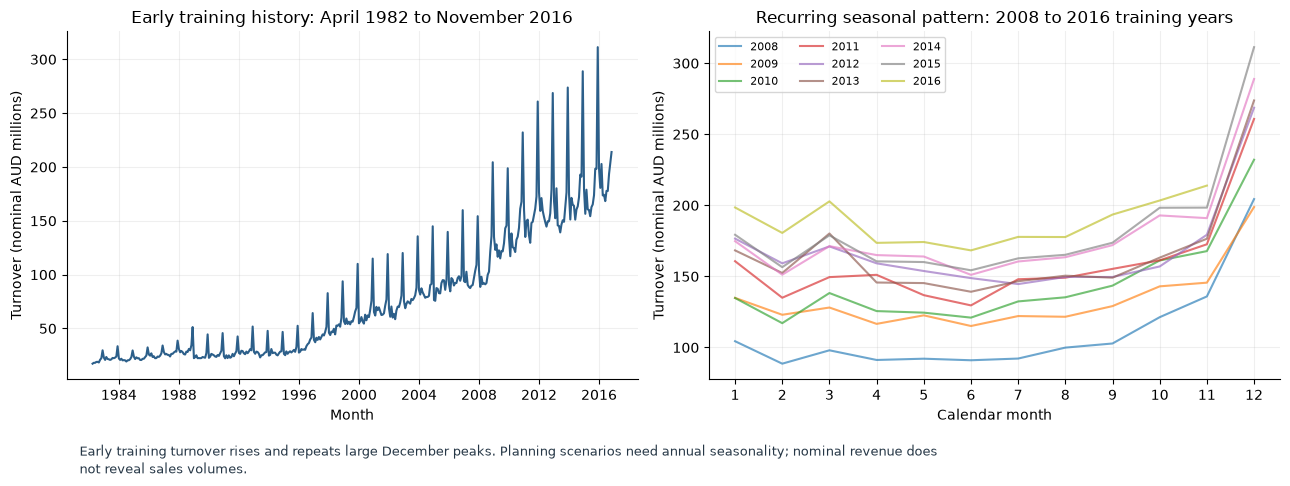

In [4]:
# Inspect only the first training window; later observations do not set candidate structures.
# Reuse exploration_train and its log seasonal differences in the appendix diagnostics.
exploration_train = assignment.loc[:"2016-11-01"]
assert exploration_train.index.max() < pd.Timestamp("2016-12-01")
seasonal_frame = exploration_train.rename("turnover").to_frame()
seasonal_frame["year"] = seasonal_frame.index.year
seasonal_frame["calendar_month"] = seasonal_frame.index.month
recent_years = seasonal_frame.loc[seasonal_frame["year"] >= 2008]
log_seasonal_difference = np.log(exploration_train).diff(12).dropna()
stl = STL(np.log(exploration_train), period=12, robust=True).fit()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(exploration_train.index, exploration_train.to_numpy(), color="#2c5f8a")
axes[0].set(title="Early training history: April 1982 to November 2016",
            ylabel="Turnover (nominal AUD millions)", xlabel="Month")
for year, group in recent_years.groupby("year"):
    axes[1].plot(group["calendar_month"], group["turnover"], alpha=0.65, label=str(year))
axes[1].set(title="Recurring seasonal pattern: 2008 to 2016 training years",
            xlabel="Calendar month", ylabel="Turnover (nominal AUD millions)", xticks=range(1, 13))
axes[1].legend(ncol=3, fontsize=8)
figure_note(fig, "Early training turnover rises and repeats large December peaks. Planning scenarios need annual seasonality; nominal revenue does not reveal sales volumes.")
fig.savefig(DETAIL / "02_training_exploration.png", dpi=150)
plt.show()


**Figure 02.** The left panel shows the early training history; the right compares the
calendar-month profiles for 2008 to 2016. December is a recurring peak rather than an
isolated one-month event. That pattern gives seasonal naive a relevant business baseline
and makes seasonal ETS/SARIMA candidates reasonable to investigate. The last displayed
year is incomplete, and these historical nominal revenues cannot estimate stock volumes
or current retailer demand. The appendix shows log and difference views of the same training observations.


In [5]:
# Record the ADF and KPSS results together; their null hypotheses differ.
# Calculate diagnostics before fitting; render their explanations and plots in the appendix.
test_rows = []
for label, series in [("log turnover", np.log(exploration_train)),
                      ("seasonal difference of log", log_seasonal_difference)]:
    adf_result = adfuller(series, autolag="AIC", result_object=False)
    with warnings.catch_warnings(record=True) as recorded_warnings:
        warnings.simplefilter("always", InterpolationWarning)
        kpss_result = kpss(series, regression="c", nlags="auto")
    test_rows.append({"series": label, "ADF_statistic": adf_result[0], "ADF_pvalue": adf_result[1],
                      "ADF_lags": adf_result[2], "KPSS_statistic": kpss_result[0],
                      "KPSS_pvalue": kpss_result[1], "KPSS_lags": kpss_result[2],
                      "KPSS_note": " | ".join(str(w.message) for w in recorded_warnings)})
stationarity = pd.DataFrame(test_rows)
stationarity.to_csv(DETAIL / "training_stationarity.csv", index=False)


## Choose a method using earlier months

Seasonal naive carries forward each calendar month's latest observed value. ETS updates
the level, trend and seasonal pattern; damping can moderate extrapolated growth. Log SARIMA
uses serial and annual dependence in proportional turnover changes. These are predefined
candidates, not new models chosen after reviewing the final outcomes.

Each method forecasts the same three earlier 24-month windows, ending in November 2018,
2020 and 2022. Their training histories end two years earlier. Mean validation MAE chooses
the configuration; the final 28-month period is reserved for the later comparison.
The transformation and stationarity calculations above use the first training history.
Their assumptions and complete technical output are explained in the appendix.


In [6]:
# These functions keep model fitting, forecasting and scoring consistent across stages.
# Every MASE denominator uses the train argument, never the later actuals.
CANDIDATES = {
    "Seasonal naive": {"family": "Seasonal naive"},
    "ETS(M,A,M)": {"family": "ETS", "damped": False},
    "ETS(M,Ad,M)": {"family": "ETS", "damped": True},
    **{f"Log SARIMA({p},0,0)(0,1,1)[12]": {"family": "Log SARIMA", "p": p} for p in [1, 2, 4]},
}

def seasonal_scale(train):
    scale = float(np.mean(np.abs(np.asarray(train)[12:] - np.asarray(train)[:-12])))
    assert scale > 0
    return scale

def score_forecast(actual, forecast, train):
    assert actual.index.equals(forecast.index), "Forecast/actual dates must match exactly."
    residual = actual.to_numpy() - forecast["point_AUD_m"].to_numpy()
    assert np.isfinite(residual).all()
    mae = float(np.mean(np.abs(residual)))
    return {"MAE_AUD_m": mae, "RMSE_AUD_m": float(np.sqrt(np.mean(residual ** 2))),
            "MASE": mae / seasonal_scale(train), "mean_error_AUD_m": float(np.mean(residual)),
            "n_months": len(actual), "training_seasonal_scale_AUD_m": seasonal_scale(train),
            **{f"coverage_{level}": float(np.mean((actual.to_numpy() >= forecast[f"lower_{level}"])
                                            & (actual.to_numpy() <= forecast[f"upper_{level}"]))) for level in [80, 95]},
            **{f"mean_width_{level}_AUD_m": float(np.mean(forecast[f"upper_{level}"] - forecast[f"lower_{level}"])) for level in [80, 95]}}

def fit_model(name, train):
    spec = CANDIDATES[name]
    if spec["family"] == "Seasonal naive":
        return None, {"converged": True, "warnings": "", "AIC_within_family": np.nan}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        if spec["family"] == "ETS":
            fitted = ETSModel(train, error="mul", trend="add", damped_trend=spec["damped"],
                              seasonal="mul", seasonal_periods=12, initialization_method="estimated").fit(maxiter=2000, disp=False)
        else:
            fitted = SARIMAX(np.log(train), order=(spec["p"], 0, 0), seasonal_order=(0, 1, 1, 12),
                             trend="c", enforce_stationarity=True, enforce_invertibility=True).fit(maxiter=300, disp=False)
    converged = bool(fitted.mle_retvals.get("converged", False))
    warning_text = " | ".join(dict.fromkeys(str(w.message) for w in caught))
    return fitted, {"converged": converged, "warnings": warning_text,
                    "AIC_within_family": float(fitted.aic)}

def forecast_model(name, fitted, train, horizon, seed=SEED):
    index = pd.date_range(train.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    result = pd.DataFrame(index=index)
    family = CANDIDATES[name]["family"]
    if family == "ETS":
        paths = np.asarray(fitted.simulate(horizon, anchor="end", repetitions=SIMULATIONS, rng=np.random.default_rng(seed)))
        if paths.shape != (horizon, SIMULATIONS):
            paths = paths.reshape(horizon, SIMULATIONS)
        assert np.isfinite(paths).all() and (paths > 0).all(), "Invalid ETS simulation paths."
        result["point_AUD_m"] = np.median(paths, axis=1)
        result["mean_AUD_m"] = np.mean(paths, axis=1)
        for level, tails in [(80, (0.1, 0.9)), (95, (0.025, 0.975))]:
            result[f"lower_{level}"], result[f"upper_{level}"] = np.quantile(paths, tails, axis=1)
        result["interval_method"] = "ETS simulated paths, conditional fitted parameters"
    else:
        if family == "Seasonal naive":
            log_center = np.log(np.resize(train.iloc[-12:].to_numpy(), horizon))
            seasonal_changes = np.log(train).diff(12).dropna().to_numpy()
            variance = np.var(seasonal_changes, ddof=1) * np.ceil(np.arange(1, horizon + 1) / 12)
            result["interval_method"] = "Gaussian log seasonal random walk approximation"
        else:
            prediction = fitted.get_forecast(steps=horizon)
            log_center = np.asarray(prediction.predicted_mean)
            variance = np.asarray(prediction.var_pred_mean)
            result["interval_method"] = "Gaussian SARIMA log predictive distribution"
        result["point_AUD_m"] = np.exp(log_center)
        result["mean_AUD_m"] = np.exp(log_center + 0.5 * variance)
        for level in [80, 95]:
            z = norm.ppf(0.5 + level / 200)
            result[f"lower_{level}"] = np.exp(log_center - z * np.sqrt(variance))
            result[f"upper_{level}"] = np.exp(log_center + z * np.sqrt(variance))
    numeric = result.select_dtypes("number")
    assert np.isfinite(numeric).all().all() and (numeric > 0).all().all()
    assert (result["lower_95"] <= result["lower_80"]).all()
    assert (result["lower_80"] <= result["point_AUD_m"]).all()
    assert (result["point_AUD_m"] <= result["upper_80"]).all()
    assert (result["upper_80"] <= result["upper_95"]).all()
    return result


In [7]:
# Each origin creates a fresh training sample and the same 24-month evaluation horizon.
# Store all candidate results, then freeze the choice using validation MAE only.
origins = ["2016-11-01", "2018-11-01", "2020-11-01"]
validation_rows, validation_predictions, fit_audit = [], [], []
for fold, origin in enumerate(origins, 1):
    train = assignment.loc[:origin]
    actual = assignment.loc[train.index[-1] + pd.offsets.MonthBegin(1):].iloc[:24]
    assert len(actual) == 24 and train.index.max() < actual.index.min()
    for name in CANDIDATES:
        fitted, status = fit_model(name, train)
        forecast = forecast_model(name, fitted, train, len(actual), seed=SEED + fold)
        validation_rows.append({"fold": fold, "origin": origin, "model": name,
                                "family": CANDIDATES[name]["family"], **score_forecast(actual, forecast, train)})
        fit_audit.append({"stage": "validation", "fold": fold, "origin": origin, "model": name, **status})
        saved = forecast.assign(actual_AUD_m=actual, model=name, fold=fold, origin=origin)
        validation_predictions.append(saved.reset_index(names="month"))
    print(f"Completed validation fold {fold}: origin {origin}, {len(train)} training months.")

validation_metrics = pd.DataFrame(validation_rows)
fit_audit_frame = pd.DataFrame(fit_audit)
validation_summary = (validation_metrics.groupby(["model", "family"], as_index=False)
                      [["MAE_AUD_m", "RMSE_AUD_m", "MASE"]].mean())
eligibility = fit_audit_frame.groupby("model")["converged"].all()
validation_summary["all_folds_converged"] = validation_summary["model"].map(eligibility)
validation_summary = validation_summary.sort_values(["MAE_AUD_m", "model"])
eligible = validation_summary.loc[validation_summary["all_folds_converged"]]
assert eligible["family"].nunique() == 3, "At least one eligible model per family is required."
representatives = eligible.groupby("family", sort=False).first()["model"].tolist()
chosen_model = eligible.iloc[0]["model"]
selection = {"criterion": "mean 24-month validation MAE across three earlier origins",
             "chosen_model": chosen_model, "family_representatives": representatives,
             "origins": origins, "test_origin": "2022-11-01", "selected_without_final_evaluation": True}
display(validation_summary.round(4))
display(validation_metrics.pivot(index="model", columns="origin", values="MAE_AUD_m").round(3))
display(fit_audit_frame[["origin", "model", "converged", "warnings"]])
validation_metrics.to_csv(DETAIL / "validation_metrics.csv", index=False)
validation_summary.to_csv(DETAIL / "validation_model_ranking.csv", index=False)
pd.concat(validation_predictions, ignore_index=True).to_csv(DETAIL / "validation_predictions.csv", index=False)
(DETAIL / "frozen_model_selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
display(Markdown(f"**Frozen decision:** `{chosen_model}` has the lowest eligible average validation MAE. "
                 "The family representatives and configuration are now fixed before final evaluation."))


Completed validation fold 1: origin 2016-11-01, 416 training months.


Completed validation fold 2: origin 2018-11-01, 440 training months.


Completed validation fold 3: origin 2020-11-01, 464 training months.


,model,family,MAE_AUD_m,RMSE_AUD_m,MASE,all_folds_converged
3,"Log SARIMA(2,0,0)(0,1,1)[12]",Log SARIMA,18.4343,25.3996,2.4748,True
4,"Log SARIMA(4,0,0)(0,1,1)[12]",Log SARIMA,18.7678,25.8572,2.5136,True
2,"Log SARIMA(1,0,0)(0,1,1)[12]",Log SARIMA,22.3443,29.0525,2.9309,True
0,"ETS(M,A,M)",ETS,22.7592,31.6462,3.0675,True
1,"ETS(M,Ad,M)",ETS,25.3256,34.3681,3.4358,True
5,Seasonal naive,Seasonal naive,36.1597,50.1253,4.6820,True


origin,2016-11-01,2018-11-01,2020-11-01
model,,,
"ETS(M,A,M)",8.912,40.030,19.336
"ETS(M,Ad,M)",12.359,43.953,19.665
"Log SARIMA(1,0,0)(0,1,1)[12]",6.995,33.384,26.655
"Log SARIMA(2,0,0)(0,1,1)[12]",6.114,32.729,16.460
"Log SARIMA(4,0,0)(0,1,1)[12]",5.836,33.178,17.289
Seasonal naive,16.092,42.571,49.817


,origin,model,converged,warnings
0,2016-11-01,Seasonal naive,True,
1,2016-11-01,"ETS(M,A,M)",True,
2,2016-11-01,"ETS(M,Ad,M)",True,
3,2016-11-01,"Log SARIMA(1,0,0)(0,1,1)[12]",True,
4,2016-11-01,"Log SARIMA(2,0,0)(0,1,1)[12]",True,
5,2016-11-01,"Log SARIMA(4,0,0)(0,1,1)[12]",True,
6,2018-11-01,Seasonal naive,True,
7,2018-11-01,"ETS(M,A,M)",True,
8,2018-11-01,"ETS(M,Ad,M)",True,
9,2018-11-01,"Log SARIMA(1,0,0)(0,1,1)[12]",True,


**Frozen decision:** `Log SARIMA(2,0,0)(0,1,1)[12]` has the lowest eligible average validation MAE. The family representatives and configuration are now fixed before final evaluation.

The validation-selected SARIMA model had mean MAE **AUD 18.43 million** across the earlier
windows, compared with **AUD 36.16 million** for seasonal naive. This justified testing the
SARIMA candidate on later observations. It did not establish that the earlier advantage
would persist. The choice is written to `.generated/frozen_model_selection.json` before the
final evaluation calculations below. Validation windows span different conditions, and
their 24-month horizon differs from the final period's 28 months.


## Test the November 2022 decision on later turnover

Refit the frozen family representatives on the same assignment history through November
2022, then forecast all 28 later months without updating inside the evaluation window.
The source extension supplies the outcomes only after that origin.


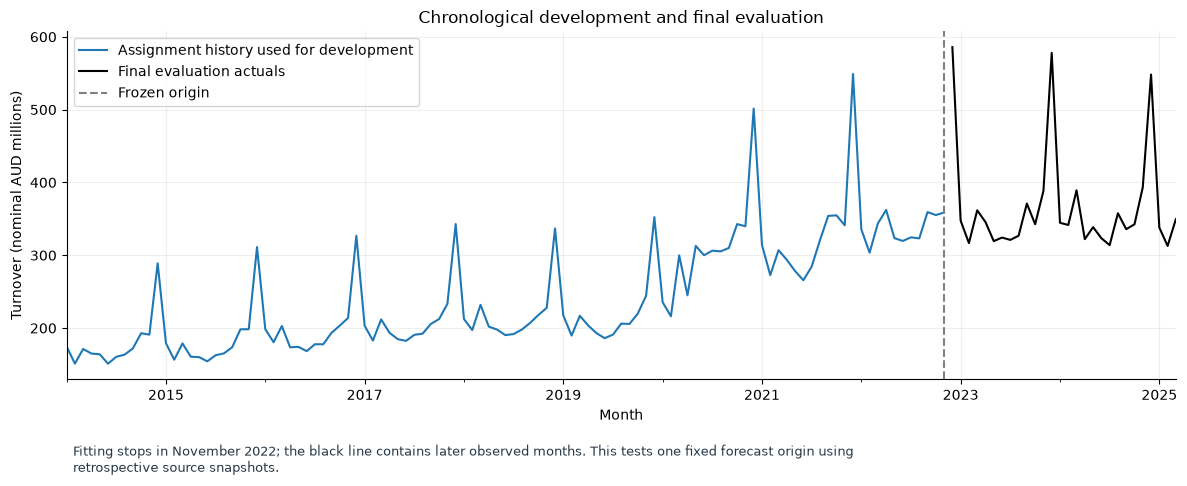

In [8]:
# Refit the already selected family representatives on history through November 2022.
# Compare their forecasts with evaluation actuals without changing the frozen choice.
fig, ax = plt.subplots()
assignment.loc["2014":].plot(ax=ax, label="Assignment history used for development")
evaluation.plot(ax=ax, label="Final evaluation actuals", color="black")
ax.axvline(pd.Timestamp("2022-11-01"), color="grey", linestyle="--", label="Frozen origin")
ax.set(title="Chronological development and final evaluation", ylabel="Turnover (nominal AUD millions)", xlabel="Month")
ax.legend()
figure_note(fig, "Fitting stops in November 2022; the black line contains later observed months. This tests one fixed forecast origin using retrospective source snapshots.")
fig.savefig(DETAIL / "01_chronological_split.png", dpi=150)
plt.show()


**Figure 01.** The colored history is the assignment snapshot used for fitting; the black
line is the extension actuals for December 2022 to March 2025. The change
in recent turnover levels makes extrapolation risk relevant to the planning question.
A forecast must be judged against what followed, not how well it fitted the colored line.
The graph does not establish a pandemic, policy or licensing cause for the earlier change;
release-vintage and publication-lag uncertainty also remains.


In [9]:
evaluation_rows, evaluation_predictions, evaluation_fits = [], [], {}
for number, name in enumerate(representatives):
    fitted, status = fit_model(name, assignment)
    assert status["converged"], f"Final-evaluation fit did not converge: {name}"
    forecast = forecast_model(name, fitted, assignment, len(evaluation), seed=SEED + 10)
    evaluation_fits[name] = fitted
    evaluation_rows.append({"model": name, "chosen_on_validation": name == chosen_model,
                            **score_forecast(evaluation, forecast, assignment)})
    fit_audit.append({"stage": "final_evaluation", "fold": None, "origin": "2022-11-01", "model": name, **status})
    evaluation_predictions.append(forecast.assign(actual_AUD_m=evaluation, model=name).reset_index(names="month"))

evaluation_metrics = pd.DataFrame(evaluation_rows).sort_values("MAE_AUD_m")
evaluation_prediction_frame = pd.concat(evaluation_predictions, ignore_index=True)
display(evaluation_metrics.round(4))
evaluation_metrics.to_csv(OUT / "evaluation_metrics.csv", index=False)
evaluation_prediction_frame.to_csv(OUT / "evaluation_predictions.csv", index=False)
selected_metrics = evaluation_metrics.set_index("model").loc[chosen_model]
baseline_metrics = evaluation_metrics.set_index("model").loc["Seasonal naive"]
relative_mae_reduction = 100 * (1 - selected_metrics["MAE_AUD_m"] / baseline_metrics["MAE_AUD_m"])
display(Markdown(
    f"The model chosen before final evaluation, **{chosen_model}**, has final MAE **AUD {selected_metrics['MAE_AUD_m']:.2f} million**, "
    f"RMSE **AUD {selected_metrics['RMSE_AUD_m']:.2f} million**, and MASE **{selected_metrics['MASE']:.3f}**. "
    f"Its MAE reduction relative to the seasonal-naive baseline is **{relative_mae_reduction:.1f}%** "
    "(a negative value means worse performance). This is retrospective forecast evidence, not a realized business benefit."
))


,model,chosen_on_validation,MAE_AUD_m,RMSE_AUD_m,MASE,mean_error_AUD_m,n_months,training_seasonal_scale_AUD_m,coverage_80,coverage_95,mean_width_80_AUD_m,mean_width_95_AUD_m
1,"ETS(M,A,M)",False,16.5282,21.3348,1.6061,-7.8788,28,10.2912,1.0,1.0,129.9056,198.2986
2,Seasonal naive,False,17.1714,21.6451,1.6686,8.2714,28,10.2912,1.0,1.0,130.6989,201.5425
0,"Log SARIMA(2,0,0)(0,1,1)[12]",True,23.3614,30.7205,2.2700,-15.2031,28,10.2912,1.0,1.0,119.3388,183.6325


The model chosen before final evaluation, **Log SARIMA(2,0,0)(0,1,1)[12]**, has final MAE **AUD 23.36 million**, RMSE **AUD 30.72 million**, and MASE **2.270**. Its MAE reduction relative to the seasonal-naive baseline is **-36.0%** (a negative value means worse performance). This is retrospective forecast evidence, not a realized business benefit.

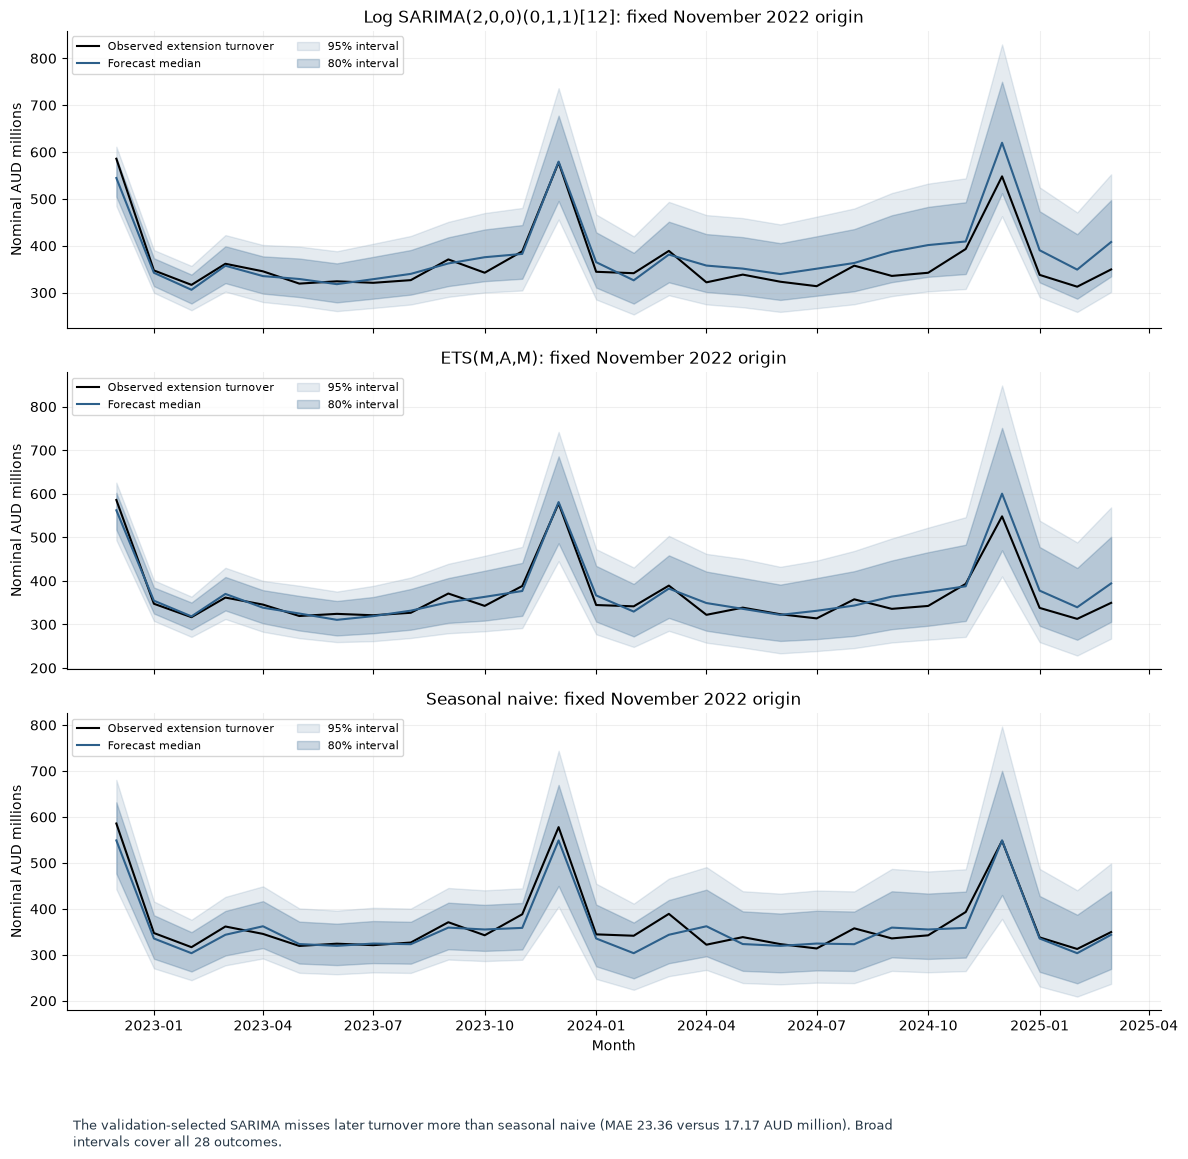

In [10]:
# Reuse saved evaluation predictions for plots and yearly error summaries.
# Keep month counts visible because the first and last years are incomplete.
fig, axes = plt.subplots(len(representatives), 1, figsize=(12, 4 * len(representatives)), sharex=True)
for ax, name in zip(np.atleast_1d(axes), representatives):
    prediction = evaluation_prediction_frame.loc[evaluation_prediction_frame["model"] == name].set_index("month")
    ax.plot(evaluation.index, evaluation, color="black", label="Observed extension turnover")
    ax.plot(prediction.index, prediction["point_AUD_m"], color="#2c5f8a", label="Forecast median")
    ax.fill_between(prediction.index, prediction["lower_95"], prediction["upper_95"], color="#2c5f8a", alpha=.12, label="95% interval")
    ax.fill_between(prediction.index, prediction["lower_80"], prediction["upper_80"], color="#2c5f8a", alpha=.25, label="80% interval")
    ax.set(title=f"{name}: fixed November 2022 origin", ylabel="Nominal AUD millions")
    ax.legend(fontsize=8, ncol=2)
axes[-1].set_xlabel("Month")
figure_note(fig, "The validation-selected SARIMA misses later turnover more than seasonal naive (MAE 23.36 versus 17.17 AUD million). Broad intervals cover all 28 outcomes.")
fig.savefig(OUT / "05_final_evaluation_forecasts.png", dpi=150)
plt.show()


**Figure 05, top row (selected SARIMA).** The forecast follows the annual peaks, but its
later central path rises above observed turnover. Its full-period MAE of AUD 23.36 million
is 36.05% above seasonal naive's. This is a reason to retain the simpler baseline for the
next assessment; the chart cannot identify the external cause of the changed pattern.

**Figure 05, middle row (ETS).** ETS tracks this evaluation period more closely overall,
with MAE AUD 16.53 million. That is the best observed comparison here, not a replacement
selected with independent evidence. A new assessment is needed before promoting it after
seeing the final result.

**Figure 05, bottom row (seasonal naive).** Repeating the last observed annual profile
misses some monthly movements but gives MAE AUD 17.17 million. It remains an understandable
reference for the next forward comparison. It does not adjust to a new trend within this
fixed-origin horizon.

**Intervals in all three rows.** Every observed month lies inside even the 80% band.
Narrower intervals would not automatically be more accurate: interval coverage and width
must be considered together. Here broad ranges hedge error, while 28 dependent monthly
outcomes provide limited evidence of calibration. Exact errors, coverage and widths are
in [the final metrics](outputs/evaluation_metrics.csv).


In [11]:
annual_error = (evaluation_prediction_frame.assign(year=lambda d: d["month"].dt.year,
                   absolute_error=lambda d: np.abs(d["actual_AUD_m"] - d["point_AUD_m"]))
                .groupby(["model", "year"]).agg(MAE_AUD_m=("absolute_error", "mean"),
                                               months=("absolute_error", "size")).reset_index())
display(annual_error.round(3))
annual_error.to_csv(DETAIL / "evaluation_error_by_year.csv", index=False)
display(Markdown("2022 has one assessed month and 2025 has three; their errors must not be treated as full-year estimates."))


,model,year,MAE_AUD_m,months
0,"ETS(M,A,M)",2022,23.686,1
1,"ETS(M,A,M)",2023,8.833,12
2,"ETS(M,A,M)",2024,18.520,12
3,"ETS(M,A,M)",2025,36.959,3
4,"Log SARIMA(2,0,0)(0,1,1)[12]",2022,41.183,1
5,"Log SARIMA(2,0,0)(0,1,1)[12]",2023,9.637,12
6,"Log SARIMA(2,0,0)(0,1,1)[12]",2024,29.147,12
7,"Log SARIMA(2,0,0)(0,1,1)[12]",2025,49.177,3
8,Seasonal naive,2022,36.800,1
9,Seasonal naive,2023,13.192,12


2022 has one assessed month and 2025 has three; their errors must not be treated as full-year estimates.

The selected SARIMA's MAE rises from **AUD 9.64 million in 2023** to **AUD 29.15 million
in 2024**. The 2025 row covers only three months; its larger error is not a full-year estimate.
The deterioration strengthens the case for monitoring performance over time rather than
assuming the validation advantage will continue. It remains a descriptive change, not an
identified cause. Source: [embedded yearly errors and month counts](#test-the-november-2022-decision-on-later-turnover).

## Broad uncertainty limits the budget interpretation

For the selected SARIMA, the average interval width is **AUD 119.34 million at 80%** and
**AUD 183.63 million at 95%** across the final period. Those are substantial ranges around
a central revenue estimate, even though all observations were covered. A planner would
need an agreed tolerance for forecast misses and a loss/cost model before treating either
band as a budget boundary. Parameter uncertainty, unexpected future changes and revisions
are not included. Training residuals also retain dependence; the supporting diagnostics
and their degrees-of-freedom caveats are in the technical appendix.


In [12]:
# Reuse the final evaluation metrics to inspect coverage beside interval width.
coverage_table = evaluation_metrics[["model", "coverage_80", "coverage_95",
                                     "mean_width_80_AUD_m", "mean_width_95_AUD_m"]].copy()
display(coverage_table.round(4))


,model,coverage_80,coverage_95,mean_width_80_AUD_m,mean_width_95_AUD_m
1,"ETS(M,A,M)",1.0,1.0,129.9056,198.2986
2,Seasonal naive,1.0,1.0,130.6989,201.5425
0,"Log SARIMA(2,0,0)(0,1,1)[12]",1.0,1.0,119.3388,183.6325


## Recommendation and dated outlook

Keep seasonal naive as the reference in the next forward assessment. Investigate ETS as
a candidate using new months, rather than turning its best observed final-period result
into a validated operational choice. Agree the planning horizon and cost of over/underforecast,
then monitor errors and interval coverage by horizon. The aggregate nominal series needs
a comparability check before it can inform a retailer's own revenue or volume planning.

The plot below retains the **frozen SARIMA configuration** and refits it on all extension
observations through March 2025. It shows what that model would project from that historical
origin. Its April 2025 to March 2027 estimates are an illustrative output, not the method
recommended for current budgeting and not a current October 2026 outlook.

The original IA3/IA4 discussion noted annual December peaks and widening uncertainty.
The present model output supports those descriptions. It does not establish that a policy
or pandemic caused a trend, or that this later forecast has achieved measured accuracy.


,interval_method,point_AUD_m,mean_AUD_m,lower_80,upper_80,lower_95,upper_95
2025-04-01,Gaussian SARIMA log predictive distribution,326.292,326.858,302.580,351.862,290.733,366.200
2025-05-01,Gaussian SARIMA log predictive distribution,322.754,323.482,296.152,351.746,282.969,368.134
2025-06-01,Gaussian SARIMA log predictive distribution,317.034,318.001,286.857,350.384,272.064,369.437
2025-07-01,Gaussian SARIMA log predictive distribution,321.680,322.848,288.438,358.754,272.255,380.079
2025-08-01,Gaussian SARIMA log predictive distribution,342.400,343.837,304.513,385.002,286.185,409.659
2025-09-01,Gaussian SARIMA log predictive distribution,359.369,361.052,317.494,406.767,297.340,434.339
2025-10-01,Gaussian SARIMA log predictive distribution,365.308,367.182,320.899,415.864,299.619,445.401
2025-11-01,Gaussian SARIMA log predictive distribution,394.126,396.302,344.526,450.867,320.848,484.139
2025-12-01,Gaussian SARIMA log predictive distribution,591.278,594.753,514.682,679.273,478.237,731.039
2026-01-01,Gaussian SARIMA log predictive distribution,365.406,367.669,316.902,421.333,293.889,454.326


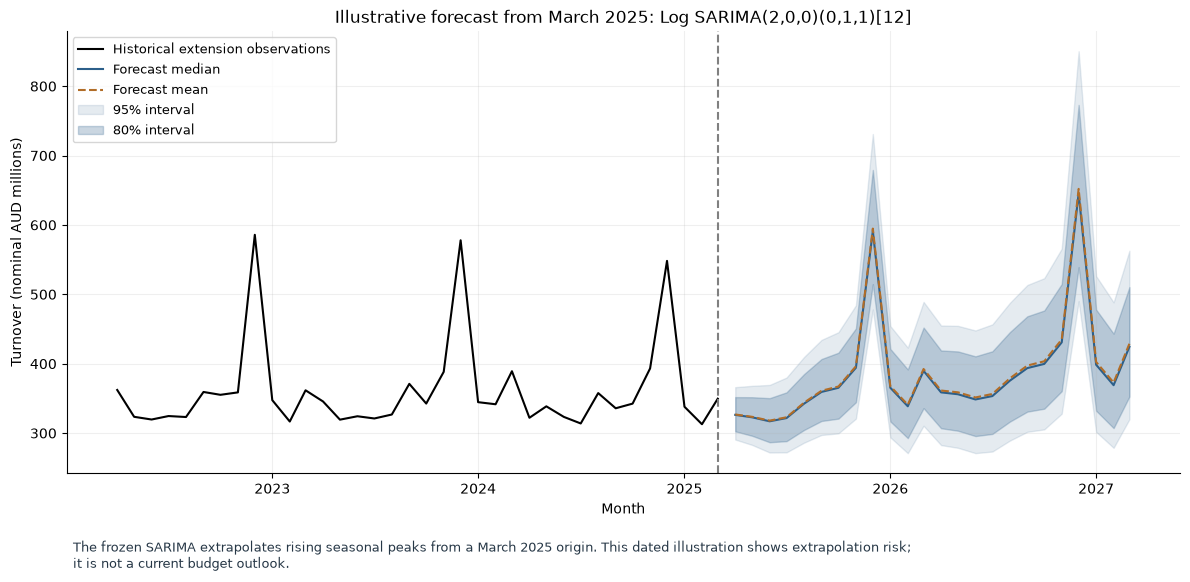

In [13]:
# Refit the frozen configuration on the full extension snapshot after evaluation.
# These dated future estimates have no later actuals available for scoring here.
future_fit, future_status = fit_model(chosen_model, extension)
assert future_status["converged"], "Dated forecast fit did not converge."
future_forecast = forecast_model(chosen_model, future_fit, extension, 24, seed=SEED + 20)
fit_audit.append({"stage": "dated_refit", "fold": None, "origin": "2025-03-01", "model": chosen_model, **future_status})
future_forecast.to_csv(DETAIL / "dated_forecast_apr2025_mar2027.csv", index_label="month")
display(future_forecast.round(3))
fig, ax = plt.subplots(figsize=(12, 6))
plot_history = extension.loc["2022-04-01":]
ax.plot(plot_history.index, plot_history.to_numpy(), label="Historical extension observations", color="black")
ax.plot(future_forecast.index, future_forecast["point_AUD_m"], label="Forecast median", color="#2c5f8a")
ax.plot(future_forecast.index, future_forecast["mean_AUD_m"], label="Forecast mean", color="#b16d28", linestyle="--")
ax.fill_between(future_forecast.index, future_forecast["lower_95"], future_forecast["upper_95"], alpha=.12, color="#2c5f8a", label="95% interval")
ax.fill_between(future_forecast.index, future_forecast["lower_80"], future_forecast["upper_80"], alpha=.25, color="#2c5f8a", label="80% interval")
ax.axvline(extension.index[-1], color="grey", linestyle="--")
ax.set(title=f"Illustrative forecast from March 2025: {chosen_model}", ylabel="Turnover (nominal AUD millions)", xlabel="Month")
ax.legend(fontsize=9)
figure_note(fig, "The frozen SARIMA extrapolates rising seasonal peaks from a March 2025 origin. This dated illustration shows extrapolation risk; it is not a current budget outlook.")
fig.savefig(DETAIL / "07_dated_future_forecast.png", dpi=150)
plt.show()


**Figure 07.** The black line is observed extension turnover through March 2025; the blue
and dashed orange lines are the refitted SARIMA median and mean for the next 24 months.
December peaks rise in the model's central path, while uncertainty generally grows across horizons with seasonal variation.
That extrapolation should be challenged before any planning use, particularly after the
earlier selected model lost to the baseline. A mean represents expected revenue under the
fitted distribution; it does not solve that model's misspecification or represent a retailer's
own expected revenue. Later actuals were not supplied to score these forecasts.

The ABS confirms that the [June 2025 reference period](https://www.abs.gov.au/statistics/industry/retail-and-wholesale-trade/retail-trade-australia/jun-2025)
was the final Retail Trade publication, released on 31 July 2025. Replacement indicators
have different scopes. Operational monitoring therefore also requires a current, comparable
data source rather than appending an incompatible index to this nominal industry series.


## Technical appendix: how the evidence was produced

The business recommendation rests on the fixed-origin comparison above. This appendix
explains the transformations, training diagnostics, residual checks, metric definitions and
source adaptation that support the experiment. The training transformations and tests were
calculated before model fitting; the following cells render those already computed values.
No final outcome changes the candidate set, configuration or selection rule.

### Transformation and seasonal change


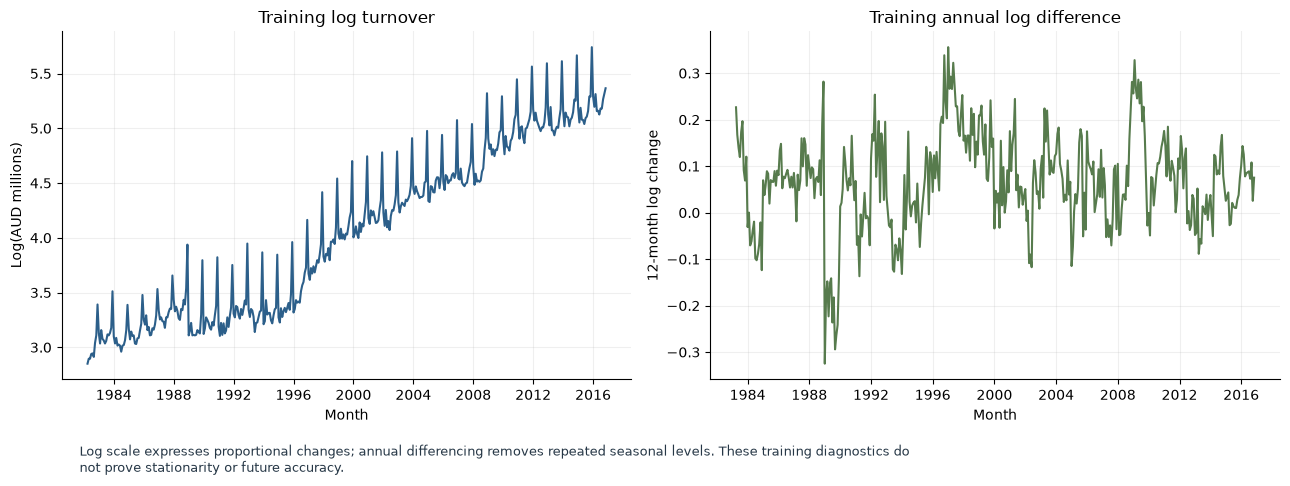

In [14]:
# Render the same training transformations calculated before model fitting.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(exploration_train.index, np.log(exploration_train), color="#2c5f8a")
axes[0].set(title="Training log turnover", ylabel="Log(AUD millions)", xlabel="Month")
axes[1].plot(log_seasonal_difference.index, log_seasonal_difference, color="#577b4d")
axes[1].set(title="Training annual log difference", ylabel="12-month log change", xlabel="Month")
figure_note(fig, "Log scale expresses proportional changes; annual differencing removes repeated seasonal levels. These training diagnostics do not prove stationarity or future accuracy.")
fig.savefig(DETAIL / "08_training_transformations.png", dpi=150)
plt.show()


**Figure 08.** The left panel displays log turnover from the first training history; the
right displays its 12-month log difference. The log scale makes proportional changes easier
to inspect, while seasonal differences reduce the repeated annual pattern. These panels
motivate checking the assumptions behind log SARIMA. A quieter differenced plot alone
does not prove stationarity, independent errors or useful forecasts. These panels use the same early training history as Figure 02.


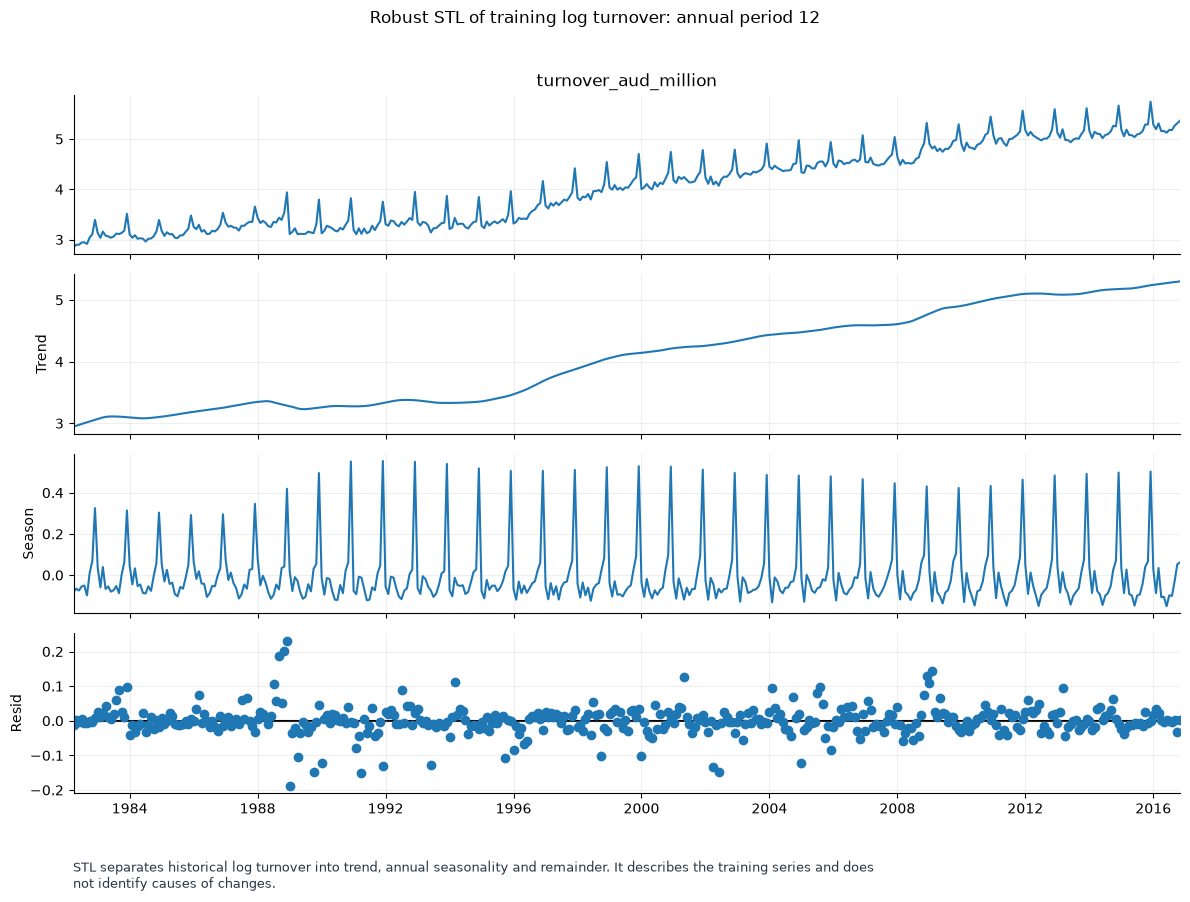

In [15]:
# Render the robust STL decomposition already calculated from early training log turnover.
fig = stl.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Robust STL of training log turnover: annual period 12", y=0.998)
figure_note(fig, "STL separates historical log turnover into trend, annual seasonality and remainder. It describes the training series and does not identify causes of changes.")
fig.savefig(DETAIL / "03_training_stl.png", dpi=150)
plt.show()


**Figure 03, from top to bottom.** The panels show the observed training log series,
estimated trend, annual seasonal component and remainder. The repeated seasonal component
supports models with a calendar-year structure; the remainder shows variation that those
components leave unexplained. This is a description of past nominal turnover, not evidence
that a seasonal model will dominate the baseline or that an external event caused a change.


,series,ADF_statistic,ADF_pvalue,ADF_lags,KPSS_statistic,KPSS_pvalue,KPSS_lags,KPSS_note
0,log turnover,0.299940,0.977342,15,3.254988,0.01,12,The test statistic is outside of the range of ...
1,seasonal difference of log,-3.366554,0.012153,18,0.201947,0.10,11,The test statistic is outside of the range of ...


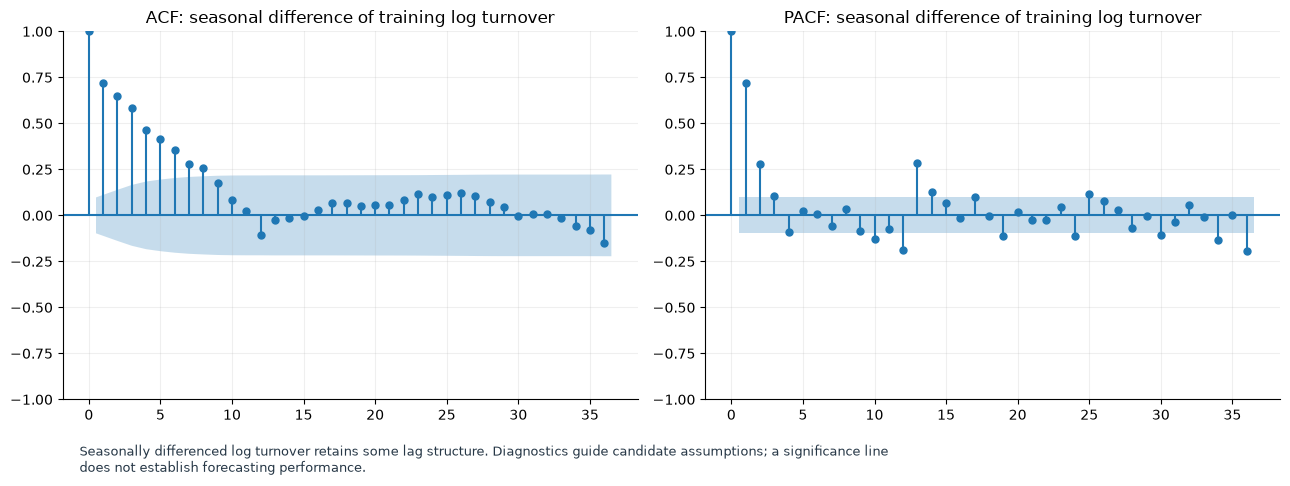

In [16]:
# Display the previously calculated tests and lag structure; do not use final outcomes.
display(stationarity)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_acf(log_seasonal_difference, lags=36, ax=axes[0])
plot_pacf(log_seasonal_difference, lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF: seasonal difference of training log turnover")
axes[1].set_title("PACF: seasonal difference of training log turnover")
figure_note(fig, "Seasonally differenced log turnover retains some lag structure. Diagnostics guide candidate assumptions; a significance line does not establish forecasting performance.")
fig.savefig(DETAIL / "04_training_acf_pacf.png", dpi=150)
plt.show()


**Figure 04.** The left ACF panel shows associations at successive lags; the right PACF
panel shows associations after adjusting for intervening lags. Remaining short-lag structure
supports investigating autoregressive candidates after seasonal differencing. The bands are
diagnostic reference lines, not business tolerances or proof of model adequacy.

The ADF null is a unit root, and KPSS's null is level stationarity. For the seasonal log
difference, ADF p = 0.01215 and KPSS reports a capped p-value of 0.1; the undifferenced log
series has a capped KPSS p-value of 0.01. These tests support examining seasonal differencing
under their assumptions, not proving that the process or selected model is adequate.
The warning notes and full values are preserved in `.generated/training_stationarity.csv`.

### Residual dependencies and forecast limitations


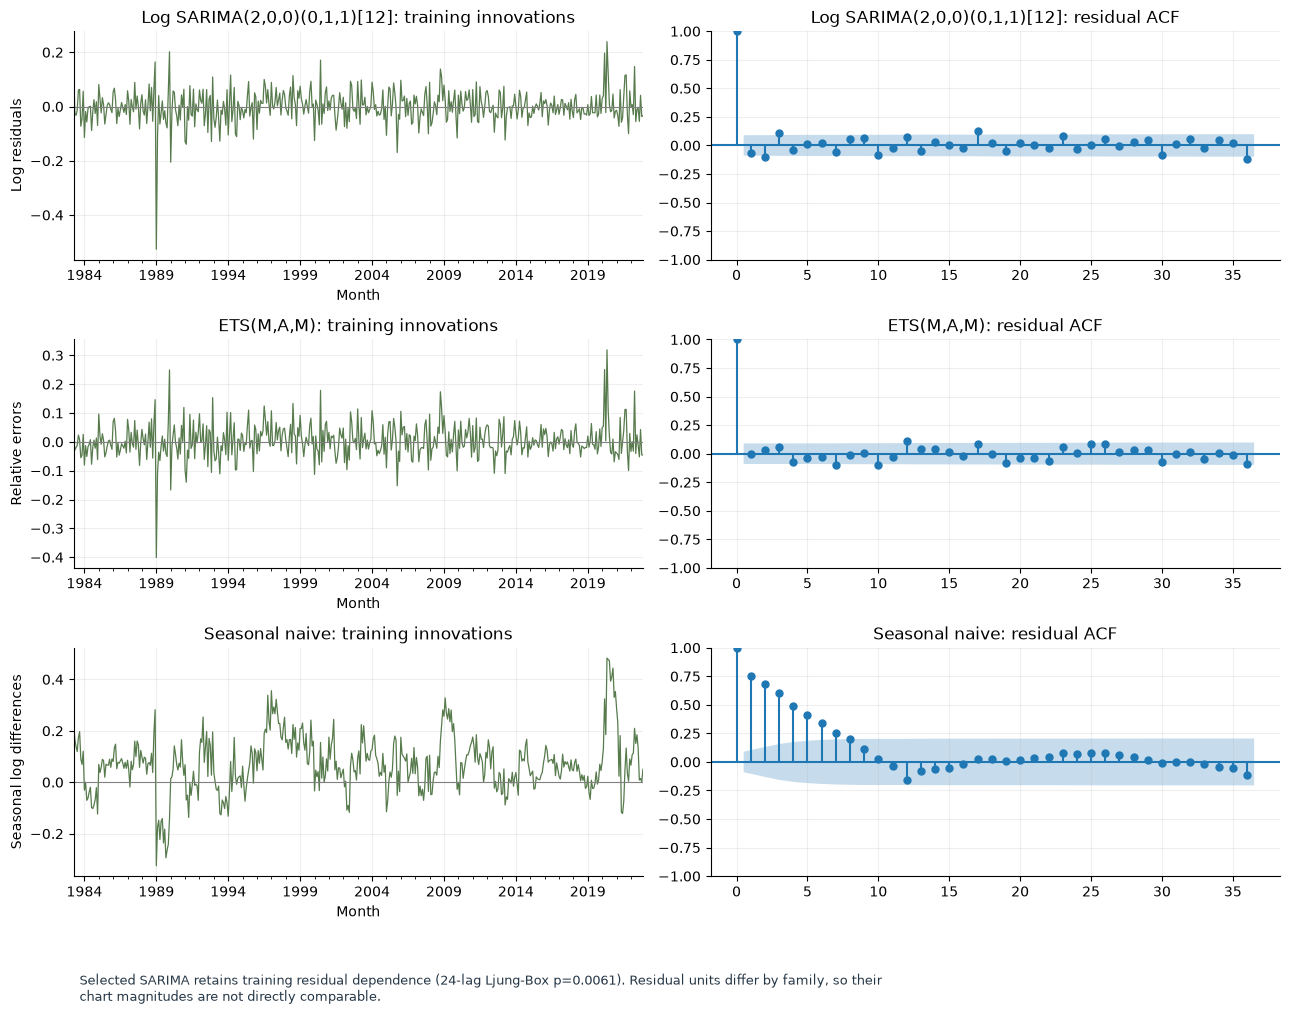

,model,lag,model_df,test_df,LB_statistic,LB_pvalue,interpretation
0,"Log SARIMA(2,0,0)(0,1,1)[12]",24,3,21,40.69885,0.00611,AR/MA degrees-of-freedom adjusted
1,"Log SARIMA(2,0,0)(0,1,1)[12]",36,3,33,58.74667,0.00380,AR/MA degrees-of-freedom adjusted
2,"ETS(M,A,M)",24,0,24,34.83559,0.07088,Unadjusted descriptive check
3,"ETS(M,A,M)",36,0,36,51.25987,0.04753,Unadjusted descriptive check
4,Seasonal naive,24,0,24,1006.13115,0.00000,Unadjusted descriptive check
5,Seasonal naive,36,0,36,1025.17916,0.00000,Unadjusted descriptive check


In [17]:
# Diagnose training innovations separately from held-out forecast errors.
# The residual units differ by model family, so their sizes are not directly comparable.
diagnostic_rows = []
fig, axes = plt.subplots(len(representatives), 2, figsize=(13, 3.5 * len(representatives)))
for row, name in enumerate(representatives):
    fitted = evaluation_fits[name]
    family = CANDIDATES[name]["family"]
    if family == "Seasonal naive":
        residuals = np.log(assignment).diff(12).dropna()
        model_df, units = 0, "Seasonal log differences"
    elif family == "ETS":
        residuals = ((assignment - fitted.fittedvalues) / fitted.fittedvalues).iloc[12:].dropna()
        model_df, units = 0, "Relative errors"
    else:
        burn = max(12, int(fitted.loglikelihood_burn))
        residuals = pd.Series(fitted.resid, index=assignment.index).iloc[burn:].dropna()
        model_df, units = CANDIDATES[name]["p"] + 1, "Log residuals"
    lb = acorr_ljungbox(residuals, lags=[24, 36], model_df=model_df, return_df=True)
    for lag, values in lb.iterrows():
        diagnostic_rows.append({"model": name, "lag": int(lag), "model_df": model_df,
                                "test_df": int(lag) - model_df,
                                "LB_statistic": values["lb_stat"], "LB_pvalue": values["lb_pvalue"],
                                "interpretation": "Unadjusted descriptive check" if model_df == 0 else "AR/MA degrees-of-freedom adjusted"})
    residuals.plot(ax=axes[row, 0], color="#577b4d", linewidth=.9)
    axes[row, 0].axhline(0, color="grey", linewidth=.8)
    axes[row, 0].set(title=f"{name}: training innovations", ylabel=units, xlabel="Month")
    plot_acf(residuals, lags=36, ax=axes[row, 1])
    axes[row, 1].set_title(f"{name}: residual ACF")
figure_note(fig, "Selected SARIMA retains training residual dependence (24-lag Ljung-Box p=0.0061). Residual units differ by family, so their chart magnitudes are not directly comparable.")
fig.savefig(DETAIL / "06_training_residual_diagnostics.png", dpi=150)
plt.show()
diagnostics = pd.DataFrame(diagnostic_rows)
display(diagnostics.round(5))
diagnostics.to_csv(DETAIL / "residual_diagnostics.csv", index=False)


**Figure 06, rows in order: selected SARIMA, ETS, seasonal naive.** Each left panel shows
training innovations; each right panel shows their ACF. The selected SARIMA's Ljung-Box
p-values are 0.0061 at lag 24 and 0.0038 at lag 36, indicating remaining dependence under
that diagnostic. The seasonal-naive ACF also shows persistent dependence. These findings
reinforce the need to monitor forecast misses instead of treating historical fit as assurance.

SARIMA residuals are log errors, ETS residuals are relative errors and seasonal-naive
residuals are seasonal log differences. Their amplitudes cannot be compared as revenue
errors across rows. SARIMA's test adjusts degrees of freedom for AR/MA coefficients;
ETS and seasonal naive use unadjusted descriptive checks. A large p-value would not prove
independent Gaussian errors, and these tests did not reselect the frozen model.
Source: [embedded residual diagnostics](#residual-dependencies-and-forecast-limitations).


### Model assumptions, scoring and prediction intervals

The candidates are predefined to keep the search small and understandable:

- **Seasonal naive:** repeat the most recent observed value for each calendar month.
- **ETS(M,A,M) and ETS(M,Ad,M):** multiplicative errors and seasonality, with an additive
  trend that is either undamped or damped. These fit turnover in its original units.
- **Log SARIMA(p,0,0)(0,1,1)[12], p=1,2,4:** nonseasonal autoregression, one seasonal
  difference and seasonal MA(1). An intercept allows average change in seasonally
  differenced log turnover. Statsmodels' intercept parameterization is not assumed
  to equal the numeric drift parameter from R/fable.

**Point forecasts:** SARIMA's `exp(mu)` is a conditional **median** when the log forecast
is Gaussian. `exp(mu + variance/2)` is the lognormal bias-corrected conditional **mean**,
conditional on fitted parameters. We report both and rank the median forecast by MAE.
ETS uses the median and mean of simulated future paths; seasonal naive uses a Gaussian
log seasonal-random-walk approximation. Evaluation predictions use the `point_AUD_m`
column, which contains medians for all three families.

**Intervals:** 80% and 95% prediction intervals use SARIMA's Gaussian log predictive
distribution, 2,000 simulated ETS paths, or log seasonal-naive variance increasing by
`ceil(h/12)`. Seasonal-naive variance is estimated from centered training seasonal log
differences. These methods condition on estimated parameters and do not include parameter
uncertainty, revisions, unexpected structural change, or external drivers. Simulation
quantiles have Monte Carlo error. No claim of guaranteed coverage is made; final empirical
coverage and interval width are reported on the held-out months.

Implementation references: [Statsmodels ETSModel](https://www.statsmodels.org/stable/generated/statsmodels.tsa.exponential_smoothing.ets.ETSModel.html)
and [SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html).


### Recorded environment and completion evidence

Package versions, data hashes and execution status are recorded below and in
`outputs/execution_summary.json`. Raw selected data and all experiment settings are
preserved. Standalone execution and saved-artifact checks are recorded in
`outputs/execution_summary.json` by this project's runner.


In [18]:
# Show the environment versions saved when the notebook started.
display(pd.Series({"python": platform.python_version(), **versions}, name="executed_version"))


python         3.12.14
numpy            2.3.5
pandas           3.0.1
scipy           1.18.1
matplotlib      3.11.2
statsmodels     0.15.0
nbformat        5.11.1
nbclient        0.11.0
ipykernel       6.29.5
Name: executed_version, dtype: str

In [19]:
# Build the recommendation from the measured results, including failures.
# Write the completion record only after the final integrity checks pass.
best_observed = evaluation_metrics.iloc[0]["model"]
selected_coverage = selected_metrics["coverage_95"]
recommendation = (
    f"Validation selected {chosen_model}; the best observed final-evaluation MAE belongs to {best_observed}. "
    f"The selected method's held-out MAE is AUD {selected_metrics['MAE_AUD_m']:.2f} million versus "
    f"AUD {baseline_metrics['MAE_AUD_m']:.2f} million for seasonal naive, with "
    f"{selected_coverage:.1%} empirical coverage for its nominal 95% interval. "
    + ("Its point-error improvement supports using it as a candidate central scenario, subject to the uncertainty and data limits. "
       if relative_mae_reduction > 0 else
       "The final period does not support replacing seasonal naive on point-error grounds; retain the baseline for the next forward assessment. ")
    + "Model choice remains frozen for the reported experiment. Operational adoption requires current data, "
      "an agreed decision loss and new forward evidence."
)
display(Markdown(recommendation))
execution = {
    "status": "executed_complete", "project": "Victoria liquor retail turnover forecasting",
    "python": platform.python_version(), "packages": versions, "random_seed": SEED,
    "ETS_simulations": SIMULATIONS, "runtime_seconds": round(time.perf_counter() - started, 2),
    "series_id": provenance["series_id"], "revision_audit": revision_summary,
    "data_hashes": {key: value["selected_sha256"] for key, value in provenance["snapshots"].items()},
    "frozen_selection": selection,
    "final_evaluation_period": [str(evaluation.index[0].date()), str(evaluation.index[-1].date())],
    "final_evaluation_metrics": evaluation_metrics.to_dict(orient="records"),
    "selected_model_MAE_reduction_percent_vs_baseline": float(relative_mae_reduction),
    "forecast_origin": "2025-03-01", "forecast_period": ["2025-04-01", "2027-03-01"],
    "recommendation": recommendation,
    "boundary": "Retrospective local execution; source ends March2025; no current forecast, deployment, or realized benefits claim.",
}
pd.DataFrame(fit_audit).to_csv(DETAIL / "fit_convergence_audit.csv", index=False)
assert evaluation_prediction_frame.groupby("model").size().eq(28).all()
assert len(future_forecast) == 24
assert all(record["converged"] for record in fit_audit if record["stage"] != "validation")
(OUT / "execution_summary.json").write_text(json.dumps(execution, indent=2, allow_nan=False), encoding="utf-8")
print(f"Complete: {len(validation_metrics)} validation assessments, {len(evaluation_metrics)} final-evaluation models, "
      f"24 dated forecast months. Elapsed: {execution['runtime_seconds']} seconds.")


Validation selected Log SARIMA(2,0,0)(0,1,1)[12]; the best observed final-evaluation MAE belongs to ETS(M,A,M). The selected method's held-out MAE is AUD 23.36 million versus AUD 17.17 million for seasonal naive, with 100.0% empirical coverage for its nominal 95% interval. The final period does not support replacing seasonal naive on point-error grounds; retain the baseline for the next forward assessment. Model choice remains frozen for the reported experiment. Operational adoption requires current data, an agreed decision loss and new forward evidence.

Complete: 18 validation assessments, 3 final-evaluation models, 24 dated forecast months. Elapsed: 38.71 seconds.
